# Adım 1: Veri Hazırlığı (HAM10000)

Bu defter şunları yapar:
1. Google Drive'da proje klasörlerini kurar
2. HAM10000 veri setini Kaggle'dan **bir kez** indirip Drive'a kaydeder
3. Veriyi inceler (sınıflar, lezyonlar, meta veri)
4. **Lezyon bazlı** eğitim / doğrulama / test ayrımını yapar ve Drive'a kaydeder
5. Her sınıftan örnek görüntüler gösterir

**Başlamadan önce:** Kaggle hesabına gir → sağ üstte profil → *Settings* → *API* → *Create New Token*. İnen `kaggle.json` dosyasını hazır tut.

Hücreleri yukarıdan aşağı sırayla çalıştır (Shift + Enter).

## 1. Drive'ı bağla ve klasörleri kur

In [13]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJE = '/content/drive/MyDrive/bitirme'
for d in ['data', 'splits', 'models', 'rag', 'results', 'logs']:
    os.makedirs(f'{PROJE}/{d}', exist_ok=True)
print('Proje klasörü:', PROJE)
print(sorted(os.listdir(PROJE)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü: /content/drive/MyDrive/bitirme
['data', 'kaggle.json', 'logs', 'models', 'rag', 'results', 'splits']


## 2. Kaggle anahtarını ayarla
İlk çalıştırmada `kaggle.json` dosyasını seçmeni ister ve Drive'a kaydeder. Sonraki oturumlarda sormaz.

In [2]:
import shutil
KAGGLE_JSON = f'{PROJE}/kaggle.json'
if not os.path.exists(KAGGLE_JSON):
    from google.colab import files
    print('Lütfen kaggle.json dosyanızı seçin')
    yuklenen = files.upload()
    shutil.move(list(yuklenen.keys())[0], KAGGLE_JSON)

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy(KAGGLE_JSON, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print('Kaggle anahtarı hazır')

Lütfen kaggle.json dosyanızı seçin


Saving kaggle.json to kaggle.json
Kaggle anahtarı hazır


## 3. Veri setini indir (yalnızca ilk seferde) ve aç
Zip dosyası Drive'a kaydedilir (yaklaşık 5-6 GB). Her yeni oturumda yalnızca Colab'ın hızlı diskine açılır; tekrar indirilmez.

In [14]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists(ZIP):
    !pip -q install kaggle
    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p {PROJE}/data
else:
    print('Zip zaten Drive\'da, indirme atlandı')

!unzip -q -n "{ZIP}" -d /content/ham
print('Açıldı: /content/ham')

Zip zaten Drive'da, indirme atlandı
Açıldı: /content/ham


## 4. Meta veriyi yükle ve görüntü yollarını eşleştir

In [15]:
import glob
import pandas as pd

meta_yolu = glob.glob('/content/ham/**/HAM10000_metadata.csv', recursive=True)[0]
meta = pd.read_csv(meta_yolu)

# Görüntü klasörleri birden fazla parçaya bölünmüş; hepsini tek sözlükte topla
yollar = {}
for p in glob.glob('/content/ham/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)
meta['path'] = meta['image_id'].map(yollar)

SINIF_ADI = {
    'nv': 'Melanositik nevüs (ben)',
    'mel': 'Melanom',
    'bkl': 'Benign keratoz',
    'bcc': 'Bazal hücreli karsinom',
    'akiec': 'Aktinik keratoz',
    'vasc': 'Vasküler lezyon',
    'df': 'Dermatofibrom',
}
meta['sinif_adi'] = meta['dx'].map(SINIF_ADI)

print('Toplam görüntü:', len(meta))
print('Yolu bulunamayan görüntü:', meta['path'].isna().sum())
meta.head(9000)

Toplam görüntü: 10015
Yolu bulunamayan görüntü: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,sinif_adi
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00274...,Benign keratoz
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00250...,Benign keratoz
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00267...,Benign keratoz
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham/ham10000_images_part_1/ISIC_00256...,Benign keratoz
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham/HAM10000_images_part_2/ISIC_00316...,Benign keratoz
...,...,...,...,...,...,...,...,...,...
8995,HAM_0001936,ISIC_0027688,nv,histo,80.0,female,lower extremity,/content/ham/ham10000_images_part_1/ISIC_00276...,Melanositik nevüs (ben)
8996,HAM_0001936,ISIC_0024704,nv,histo,80.0,female,lower extremity,/content/ham/ham10000_images_part_1/ISIC_00247...,Melanositik nevüs (ben)
8997,HAM_0006821,ISIC_0030260,nv,histo,75.0,male,upper extremity,/content/ham/HAM10000_images_part_2/ISIC_00302...,Melanositik nevüs (ben)
8998,HAM_0002861,ISIC_0031462,nv,histo,55.0,male,upper extremity,/content/ham/HAM10000_images_part_2/ISIC_00314...,Melanositik nevüs (ben)


## 5. Veriyi incele

In [5]:
print('Farklı lezyon sayısı:', meta['lesion_id'].nunique())
lezyon_basina = meta.groupby('lesion_id').size()
print('Lezyon başına görüntü sayısı dağılımı:')
print(lezyon_basina.value_counts().sort_index().to_string())

# Her lezyonun tek bir tanısı olmalı (kontrol)
print('\nHer lezyonda tek tanı var mı:', meta.groupby('lesion_id')['dx'].nunique().max() == 1)

print('\nSınıf dağılımı (görüntü):')
dag = meta['dx'].value_counts()
print(pd.DataFrame({'sinif': dag.index.map(SINIF_ADI), 'goruntu': dag.values,
                    'yuzde': (dag.values / len(meta) * 100).round(1)}).to_string(index=False))

print('\nTanı yöntemi (dx_type):')
print(meta['dx_type'].value_counts().to_string())

print('\nEksik değerler:')
print(meta[['age', 'sex', 'localization']].isna().sum().to_string())

Farklı lezyon sayısı: 7470
Lezyon başına görüntü sayısı dağılımı:
1    5514
2    1423
3     490
4      34
5       5
6       4

Her lezyonda tek tanı var mı: True

Sınıf dağılımı (görüntü):
                  sinif  goruntu  yuzde
Melanositik nevüs (ben)     6705   66.9
                Melanom     1113   11.1
         Benign keratoz     1099   11.0
 Bazal hücreli karsinom      514    5.1
        Aktinik keratoz      327    3.3
        Vasküler lezyon      142    1.4
          Dermatofibrom      115    1.1

Tanı yöntemi (dx_type):
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69

Eksik değerler:
age             57
sex              0
localization     0


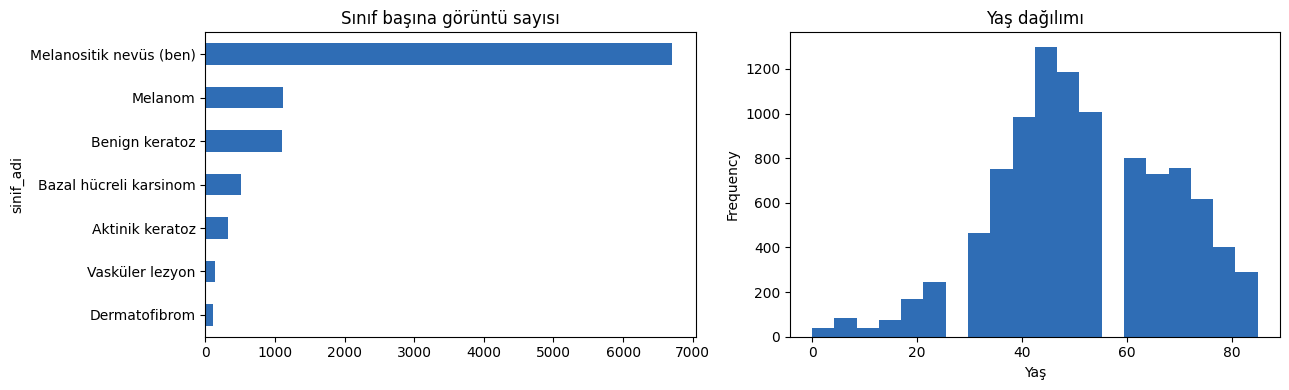

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
meta['sinif_adi'].value_counts().plot.barh(ax=ax[0], color='#2F6DB5')
ax[0].set_title('Sınıf başına görüntü sayısı'); ax[0].invert_yaxis()
meta['age'].plot.hist(bins=20, ax=ax[1], color='#2F6DB5')
ax[1].set_title('Yaş dağılımı'); ax[1].set_xlabel('Yaş')
plt.tight_layout(); plt.show()

## 6. Lezyon bazlı ayrım (en önemli adım)
Aynı lezyonun birden fazla fotoğrafı var. Ayrımı **görüntüye göre** yaparsak aynı lezyon hem eğitimde hem testte olur ve sonuçlar yapay olarak yükselir. Bu yüzden ayrımı **lezyona göre** yapıyoruz ve her sınıfın oranını korumak için tabakalı (stratified) ayırıyoruz.

Oranlar: %70 eğitim, %15 doğrulama, %15 test.

In [7]:
from sklearn.model_selection import train_test_split

lezyonlar = meta.groupby('lesion_id', as_index=False)['dx'].first()
egitim_doglama, test_lez = train_test_split(
    lezyonlar, test_size=0.15, stratify=lezyonlar['dx'], random_state=42)
egitim_lez, dogrulama_lez = train_test_split(
    egitim_doglama, test_size=0.15 / 0.85, stratify=egitim_doglama['dx'], random_state=42)

ayrim = {}
ayrim.update({l: 'egitim' for l in egitim_lez['lesion_id']})
ayrim.update({l: 'dogrulama' for l in dogrulama_lez['lesion_id']})
ayrim.update({l: 'test' for l in test_lez['lesion_id']})
meta['split'] = meta['lesion_id'].map(ayrim)

# Kontrol: hiçbir lezyon iki kümede birden olmamalı
kume_sayisi = meta.groupby('lesion_id')['split'].nunique()
assert kume_sayisi.max() == 1, 'HATA: bir lezyon birden fazla kümede!'
assert meta['split'].notna().all()
print('Kontrol geçti: hiçbir lezyon iki kümede birden yok')

tablo = pd.crosstab(meta['sinif_adi'], meta['split'])[['egitim', 'dogrulama', 'test']]
tablo.loc['TOPLAM'] = tablo.sum()
print(tablo.to_string())

Kontrol geçti: hiçbir lezyon iki kümede birden yok
split                    egitim  dogrulama  test
sinif_adi                                       
Aktinik keratoz             233         43    51
Bazal hücreli karsinom      365         72    77
Benign keratoz              775        167   157
Dermatofibrom                76         17    22
Melanom                     777        168   168
Melanositik nevüs (ben)    4730        975  1000
Vasküler lezyon              98         22    22
TOPLAM                     7054       1464  1497


## 7. Ayrımı Drive'a kaydet
Sonraki bütün adımlar bu dosyayı kullanacak; böylece herkes aynı ayrımla çalışır.

In [8]:
cikti = f'{PROJE}/splits/ham10000_split.csv'
meta.drop(columns=['path']).to_csv(cikti, index=False)
print('Kaydedildi:', cikti)

Kaydedildi: /content/drive/MyDrive/bitirme/splits/ham10000_split.csv


## 8. Her sınıftan örnek görüntüler

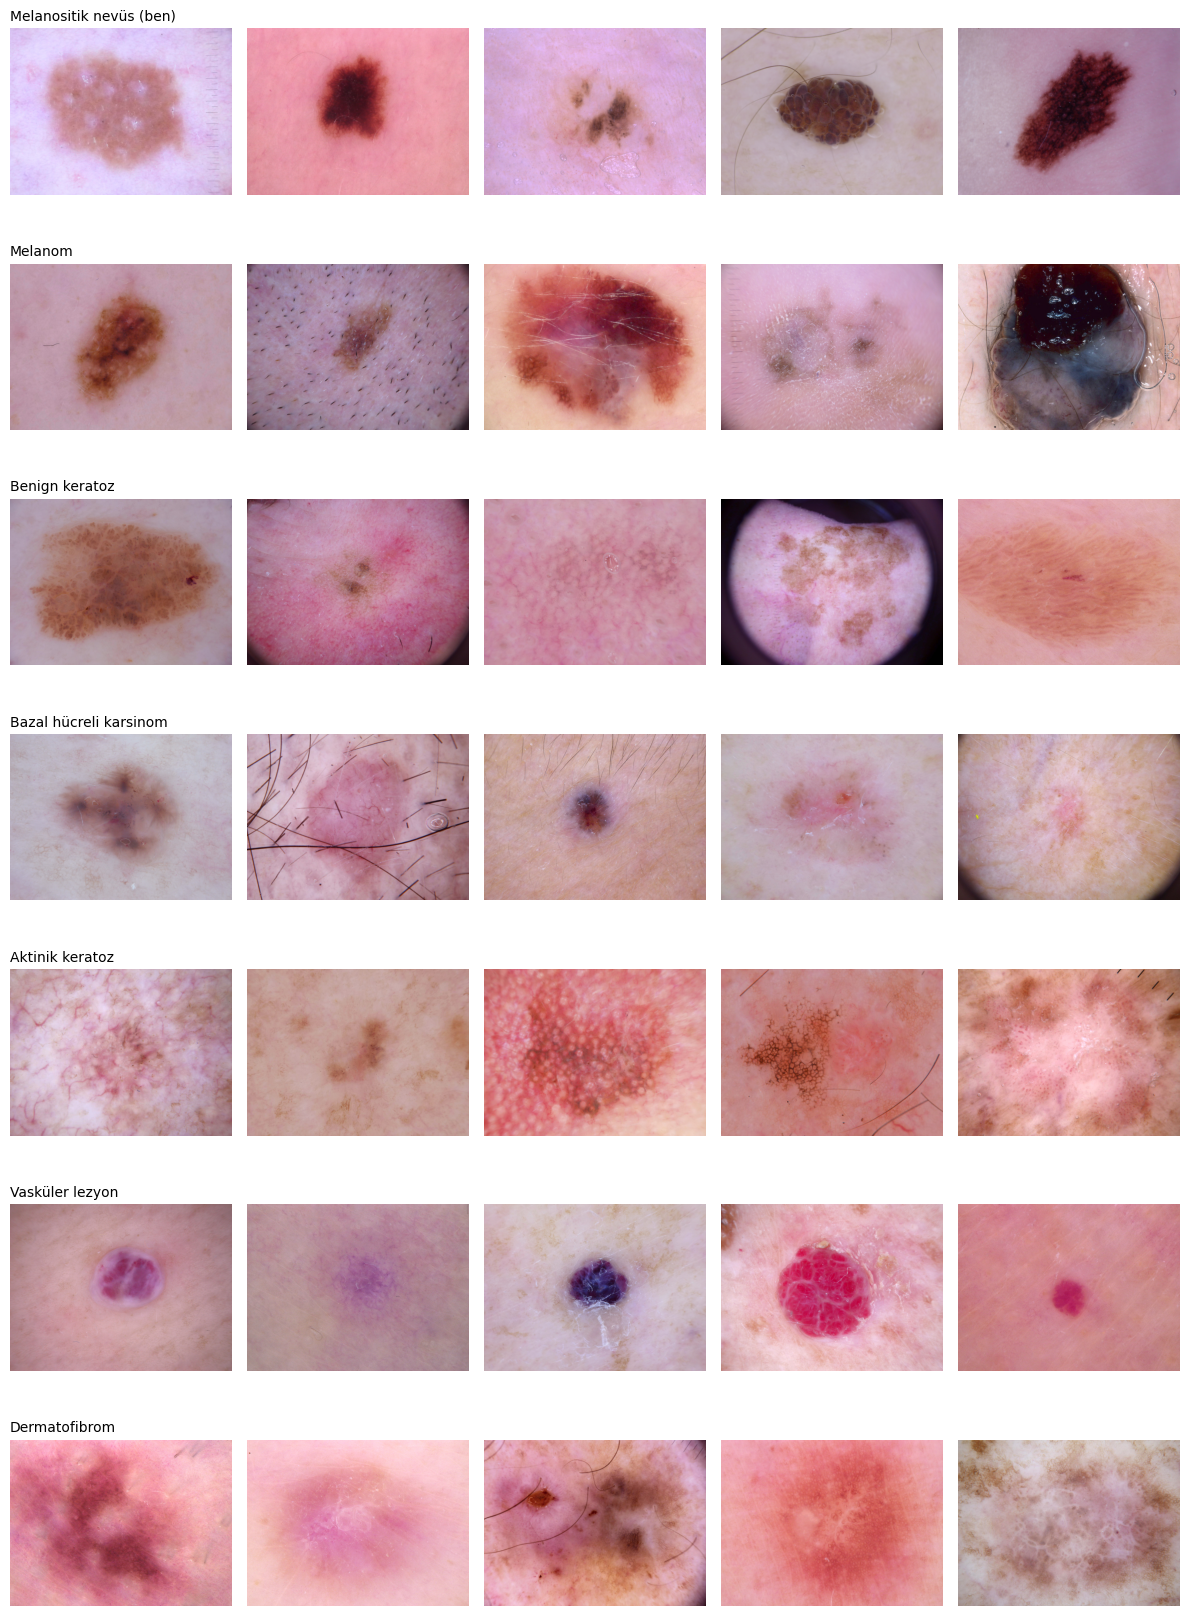

In [9]:
from PIL import Image
siniflar = list(SINIF_ADI.keys())
fig, eksen = plt.subplots(len(siniflar), 5, figsize=(12, 2.4 * len(siniflar)))
for i, s in enumerate(siniflar):
    ornek = meta[(meta['dx'] == s) & (meta['split'] == 'egitim')].sample(5, random_state=0)
    for j, (_, r) in enumerate(ornek.iterrows()):
        eksen[i, j].imshow(Image.open(r['path']))
        eksen[i, j].axis('off')
    eksen[i, 0].set_title(SINIF_ADI[s], loc='left', fontsize=10)
plt.tight_layout(); plt.show()

Görüntü boyutları: {(600, 450): 10015}
Birebir aynı dosya sayısı: 4
Farklı kümelere düşen aynı dosya: 0
'unknown' sex: 57
'unknown' localization: 234
Yaşı eksik: 57
Kaydedildi: results klasörü


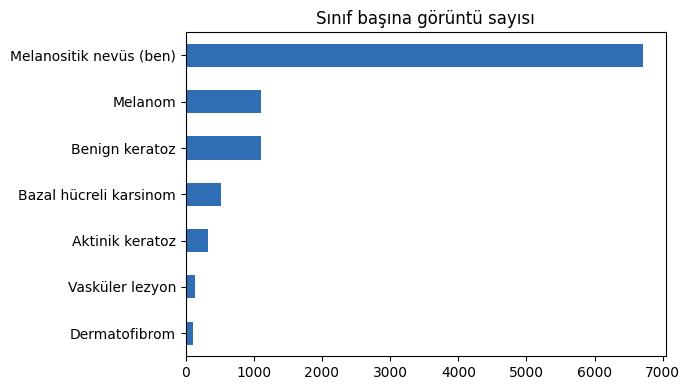

In [16]:
# Ek kontroller ve kayıtlar
import hashlib
from PIL import Image

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)

# 1) Görüntü boyutları
boyutlar = meta['path'].map(lambda p: Image.open(p).size)
print('Görüntü boyutları:', boyutlar.value_counts().to_dict())

# 2) Birebir aynı dosyalar (1-2 dakika sürebilir)
meta['md5'] = meta['path'].map(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
kopyalar = meta[meta.duplicated('md5', keep=False)]
print('Birebir aynı dosya sayısı:', len(kopyalar))
print('Farklı kümelere düşen aynı dosya:', (kopyalar.groupby('md5')['split'].nunique() > 1).sum())

# 3) 'unknown' değerler
for sutun in ['sex', 'localization']:
    print(f"'unknown' {sutun}:", (meta[sutun] == 'unknown').sum())
print('Yaşı eksik:', meta['age'].isna().sum())

# 4) Tez ve repo için kayıtlar
tablo = pd.crosstab(meta['sinif_adi'], meta['split'])[['egitim', 'dogrulama', 'test']]
tablo.to_csv(f'{PROJE}/results/01_ayrim_tablosu.csv')
meta[['image_id', 'lesion_id', 'dx', 'split']].to_csv(
    f'{PROJE}/results/ham10000_split_ids.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
meta['sinif_adi'].value_counts().plot.barh(ax=ax, color='#2F6DB5')
ax.set_title('Sınıf başına görüntü sayısı'); ax.invert_yaxis(); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/01_sinif_dagilimi.png', dpi=150)
print('Kaydedildi: results klasörü')

In [17]:
print(kopyalar.sort_values('md5')[['image_id', 'lesion_id', 'dx', 'split']])
print('Yaşı ve cinsiyeti birlikte eksik:', (meta['age'].isna() & (meta['sex'] == 'unknown')).sum())

          image_id    lesion_id  dx   split
8260  ISIC_0029861  HAM_0002300  nv  egitim
8261  ISIC_0024366  HAM_0002300  nv  egitim
8303  ISIC_0029938  HAM_0001895  nv    test
8304  ISIC_0024777  HAM_0001895  nv    test
Yaşı ve cinsiyeti birlikte eksik: 47
